# How fast can LSH identify a song?

DTU 02807 · Audio fingerprint retrieval · FMA small, release `v0.2-fingerprints`

This experiment compares Nikos’s exhaustive cosine search with a random-hyperplane locality-sensitive hashing (LSH) index on the same unit-normalised fingerprints. The outcome is the **song ID** of a distorted audio window. The report figure and held-out measurements are below.

**Measured result.** The selected 10-bit, 32-table index scored 4.4% of the catalogue per query. On 3,335 held-out clips its track accuracy was 90.76%, compared with 93.64% for exact search. LSH had lower single-query latency and exact search had higher bulk throughput on the benchmark machine.

**Run:** From the repository root, follow the [LSH notebook setup in the README](../README.md#lsh-retrieval-benchmark) and run all cells. Missing fingerprint archives are fetched from the [project release](https://github.com/nickiliak/02807_computational_tools_ds/releases/tag/v0.2-fingerprints). The notebook uses CPU and needs about 42 MB of input downloads on a fresh checkout.

In [1]:
from pathlib import Path
from time import perf_counter, perf_counter_ns
from urllib.request import urlopen
import hashlib
import os
import platform
import shutil
import sys
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from threadpoolctl import threadpool_info, threadpool_limits

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/afp/lsh.py").is_file())
sys.path.insert(0, str(ROOT / "src"))
from afp.lsh import AngularLSH
from afp.retrieval import search as exact_search

# One BLAS thread for both methods throughout this notebook.
threads = threadpool_limits(limits=1, user_api="blas")
print(platform.system(), platform.machine(), os.getenv("PROCESSOR_IDENTIFIER", platform.processor()))
print("Python", platform.python_version(), "NumPy", np.__version__,
      [(lib["internal_api"], lib["num_threads"]) for lib in threadpool_info() if lib["user_api"] == "blas"])

Windows AMD64 Intel64 Family 6 Model 183 Stepping 1, GenuineIntel
Python 3.12.11 NumPy 2.5.5 [('openblas', 1)]


## Inputs and track split

Each row is one audio window. Several reference windows can belong to the same song. Load the three release archives, verify GitHub’s SHA-256 digests and reproduce the published exact-search baseline. The manifest also includes processed songs without a surviving reference window.

For configuration selection use standard queries from a seeded 25% sample of **distinct standard-query track IDs**. Exclude those tracks from both final query sets. Keep the full reference catalogue for every test: the task is to identify a known song. TikTok-like queries never enter configuration selection.

In [2]:
DATA = ROOT / "data/processed/fingerprints"
DATA.mkdir(parents=True, exist_ok=True)
BASE = "https://github.com/nickiliak/02807_computational_tools_ds/releases/download/v0.2-fingerprints/"
DIGESTS = {
    "references.npz": "fb749ede9dd8cf363aac209d5d83ce74ca6e00a73a23ad8477d9d7ecb310fbba",
    "queries.npz": "dd6d0ef03e26158b037cd1a9842bfb2a9e88181d0ee1332fd896ce04833c802a",
    "queries_tiktok.npz": "a8095ab474849d9203bad548e76adab0773b4fc8f92791599c1e046f9138a404",
}

def release_arrays(name):
    """Download only a missing asset and verify its digest before loading the arrays."""
    path = DATA / name
    def digest(file):
        with file.open("rb") as stream:
            return hashlib.file_digest(stream, "sha256").hexdigest()
    if not path.exists():
        with tempfile.NamedTemporaryFile(dir=DATA, delete=False) as output:
            tmp = Path(output.name)
        try:
            with urlopen(BASE + name, timeout=90) as response, tmp.open("wb") as output:
                shutil.copyfileobj(response, output)
            if digest(tmp) != DIGESTS[name]:
                raise ValueError(f"Download checksum mismatch: {name}")
            tmp.replace(path)
        finally:
            tmp.unlink(missing_ok=True)
    if digest(path) != DIGESTS[name]:
        raise ValueError(f"Local checksum mismatch: {path}")
    with np.load(path, allow_pickle=False) as archive:
        return dict(archive)

reference = release_arrays("references.npz")
R, track_ids = reference["vectors"], reference["track_id"]
sets = {"Standard": release_arrays("queries.npz"), "TikTok-like": release_arrays("queries_tiktok.npz")}
for data in [reference, *sets.values()]:
    np.testing.assert_allclose(np.linalg.norm(data["vectors"], axis=1), 1, atol=2e-5)
print(f"{len(R):,} windows × {R.shape[1]} dimensions | {np.unique(track_ids).size:,} searchable tracks")
for (name, data), expected in zip(sets.items(), [1966, 1799], strict=True):
    predicted, _ = exact_search(R, track_ids, data["vectors"])
    hits = (predicted == data["track_id"]).sum()
    assert hits == expected
    print(f"Full {name}: exact search identifies {hits:,}/{len(predicted):,} songs")

standard = sets["Standard"]
standard_tracks = np.unique(standard["track_id"])
dev_tracks = np.random.default_rng(2211).choice(standard_tracks, len(standard_tracks) // 4, replace=False)
dev = np.isin(standard["track_id"], dev_tracks)
Qdev, ydev = standard["vectors"][dev], standard["track_id"][dev]
parts = []
for name, data in sets.items():
    keep = ~np.isin(data["track_id"], dev_tracks)
    parts.append((data["vectors"][keep], pd.DataFrame({
        "set": name, "distortion": data["augmentation"][keep], "track": data["track_id"][keep]
    })))
Q = np.concatenate([vectors for vectors, _ in parts])
meta = pd.concat([frame for _, frame in parts], ignore_index=True)
assert not np.intersect1d(meta.track, dev_tracks).size
print(f"Development: {len(Qdev)} queries. Final:", meta.groupby("set").size().to_dict())

35,292 windows × 256 dimensions | 7,989 searchable tracks


Full Standard: exact search identifies 1,966/2,000 songs


Full TikTok-like: exact search identifies 1,799/2,000 songs
Development: 507 queries. Final: {'Standard': 1493, 'TikTok-like': 1842}


## Build the index and select a configuration

A random hyperplane gives one bit from the sign of a projection. Close vectors in angle tend to share bits. More bits make a bucket smaller; more independent tables give a match more chances to appear. Pool the matching buckets, remove duplicate window IDs, and score the remaining windows by the same cosine rule used in exact search. Empty candidate sets count as misses. See [MMDS §3.7.2](http://www.mmds.org) and the [implementation](../src/afp/lsh.py).

Try 8, 10 and 12 bits with 8, 16 and 32 tables. Choose the lowest **mean candidate count** within two percentage points of exact development accuracy. If none qualifies, choose the most accurate. This deterministic rule avoids selecting on noisy timing. All trials use one fixed index seed. Timings include hashing, candidate lookup, deduplication, reranking and returning a track ID. Index construction is timed separately.

In [3]:
def single_query_times(lookup, queries, order):
    """Measure warm batch-size-one latency in milliseconds for a fixed query order."""
    for i in order[:15]:
        lookup(queries[i:i+1])
    elapsed = np.empty(len(order))
    for j, i in enumerate(order):
        window = queries[i:i+1]
        start = perf_counter_ns()
        lookup(window)
        elapsed[j] = (perf_counter_ns() - start) / 1e6
    return elapsed

def exact(vectors):
    """Run the repository's exhaustive cosine implementation with its default chunk size."""
    return exact_search(R, track_ids, vectors)

order = np.random.default_rng(42).permutation(len(Qdev))
dev_exact_accuracy = np.mean(exact(Qdev)[0] == ydev)
dev_exact_ms = np.median(single_query_times(exact, Qdev, order))
grid = []
for bits in (8, 10, 12):
    for tables in (8, 16, 32):
        start = perf_counter()
        index = AngularLSH(R, track_ids, bits=bits, tables=tables)
        build_s = perf_counter() - start
        matches = index.search(Qdev)
        grid.append(dict(bits=bits, tables=tables, accuracy=np.mean(matches.track == ydev),
                         mean_candidates=matches.candidates.mean(), build_s=build_s,
                         median_ms=np.median(single_query_times(index.search, Qdev, order))))
sweep = pd.DataFrame(grid)
eligible = sweep[sweep.accuracy >= dev_exact_accuracy - 0.02]
if eligible.empty:
    eligible = sweep[sweep.accuracy == sweep.accuracy.max()]
selected = eligible.sort_values(["mean_candidates", "bits", "tables"]).iloc[0]
bits, tables = int(selected.bits), int(selected.tables)
index = AngularLSH(R, track_ids, bits=bits, tables=tables)
print(f"Selected {bits} bits × {tables} tables. Exact development accuracy {dev_exact_accuracy:.2%}.")
display(sweep.round(3))

Selected 10 bits × 32 tables. Exact development accuracy 98.03%.


,bits,tables,accuracy,mean_candidates,build_s,median_ms
0,8,8,0.917,1360.574,0.033,0.407
1,8,16,0.968,2644.300,0.067,0.804
2,8,32,0.974,5070.933,0.135,1.555
3,10,8,0.815,398.475,0.043,0.060
4,10,16,0.933,780.316,0.088,0.118
5,10,32,0.970,1550.635,0.180,0.500
6,12,8,0.728,117.069,0.046,0.028
7,12,16,0.864,233.645,0.091,0.045
8,12,32,0.943,463.574,0.182,0.084


## Held-out comparison

Predict the song with the highest-scoring window. Track accuracy uses the labeled song ID. Exact agreement measures whether both methods name the same song. These are closed-catalogue trials without a rejection threshold.

For single-clip latency, use the same shuffled query order and alternate which method goes first across four warm passes. Report the median and 95th percentile across individual lookups. For offline throughput, pass the same full held-out matrix to each method and take the median of four runs, alternating order. This lets exhaustive search use its normal 256-query chunks. All timings exclude audio encoding, file loading and index construction.

In [4]:
exact_tracks, _ = exact(Q)
approx = index.search(Q)
meta["Exact"] = exact_tracks == meta.track
meta["LSH"] = approx.track == meta.track
meta["agreement"] = approx.track == exact_tracks
meta["candidates"] = approx.candidates
meta["empty"] = approx.candidates == 0

def accuracy_table(groups):
    """Summarise paired retrieval results on the same query rows."""
    return meta.groupby(groups).agg(
        queries=("track", "size"), exact_accuracy=("Exact", "mean"), lsh_accuracy=("LSH", "mean"),
        same_prediction=("agreement", "mean"), mean_candidates=("candidates", "mean"), empty=("empty", "sum"),
    )

by_set = accuracy_table("set")
display(by_set.round(4))
display(accuracy_table(["set", "distortion"]).round(4))

,queries,exact_accuracy,lsh_accuracy,same_prediction,mean_candidates,empty
set,,,,,,
Standard,1493,0.9839,0.9705,0.9792,1546.7147,0
TikTok-like,1842,0.8979,0.8567,0.9256,1572.2687,0


queries  exact_accuracy  \
set         distortion                                                 
Standard    band_pass                            142          1.0000   
            echo                                 149          1.0000   
            high_pass                            166          0.9940   
            low_pass                             141          0.9929   
            noise                                162          0.9568   
            pitch_shift                          156          0.9872   
            reverb                               141          1.0000   
            reverb+noise                         152          0.9605   
            time_stretch                         141          0.9858   
            time_stretch+pitch_shift             143          0.9650   
TikTok-like compression                          503          0.9881   
            speed_up                             422          0.9479   
            speed_up+voice_over+compression      413          0.6465   
            voice_over                           504          0.9722   

                                             lsh_accuracy  same_prediction  \
set         distortion                                                       
Standard    band_pass                              1.0000           1.0000   
            echo                                   0.9866           0.9866   
            high_pass                              0.9940           1.0000   
            low_pass                               0.9929           1.0000   
            noise                                  0.9444           0.9691   
            pitch_shift                            0.9679           0.9744   
            reverb                                 1.0000           1.0000   
            reverb+noise                           0.9474           0.9605   
            time_stretch                           0.9716           0.9858   
            time_stretch+pitch_shift               0.9021           0.9161   
TikTok-like compression                            0.9801           0.9901   
            speed_up                               0.8886           0.9289   
            speed_up+voice_over+compression        0.5666           0.7966   
            voice_over                             0.9444           0.9643   

                                             mean_candidates  empty  
set         distortion                                               
Standard    band_pass                              1553.0845      0  
            echo                                   1552.5235      0  
            high_pass                              1549.8373      0  
            low_pass                               1552.6596      0  
            noise                                  1536.0062      0  
            pitch_shift                            1556.6090      0  
            reverb                                 1523.6596      0  
            reverb+noise                           1524.6776      0  
            time_stretch                           1570.9149      0  
            time_stretch+pitch_shift               1548.4825      0  
TikTok-like compression                            1527.5089      0  
            speed_up                               1573.6066      0  
            speed_up+voice_over+compression        1611.2736      0  
            voice_over                             1583.8571      0

In [5]:
methods = {"Exact": exact, "LSH": index.search}
online = {name: [] for name in methods}
offline = {name: [] for name in methods}
for repeat in range(4):
    order = np.random.default_rng(1810 + repeat).permutation(len(Q))
    for name in (["Exact", "LSH"] if repeat % 2 == 0 else ["LSH", "Exact"]):
        lookup = methods[name]
        online[name].append(single_query_times(lookup, Q, order))
        start = perf_counter()
        lookup(Q)
        offline[name].append(perf_counter() - start)
timing = pd.DataFrame({
    name: {"median_ms": np.median(times), "p95_ms": np.percentile(times, 95),
           "bulk_queries_per_s": len(Q) / np.median(offline[name])}
    for name, times in online.items()
}).T
display(timing.round(3))
print(f"Selected index build: {selected.build_s:.3f} s. "
      f"Mean candidates: {approx.candidates.mean():,.0f} / {len(R):,}.")

,median_ms,p95_ms,bulk_queries_per_s
Exact,0.936,1.120,6642.293
LSH,0.502,0.618,2103.732


Selected index build: 0.180 s. Mean candidates: 1,561 / 35,292.


## Report figure

The development panel shows all nine configurations. Each line connects 8, 16 and 32 tables for one bit length. The right panel compares the selected configuration with exhaustive search on held-out tracks. The combined-distortion row is a subset of the TikTok-like set.

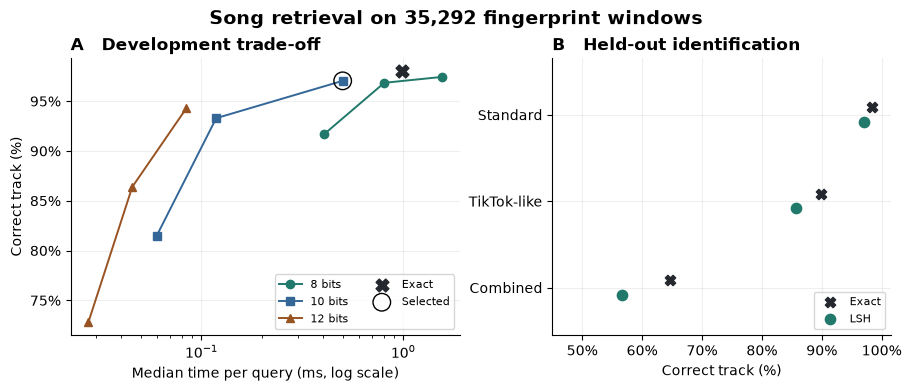

In [6]:
from matplotlib.ticker import PercentFormatter

fig, (ax, accuracy_ax) = plt.subplots(1, 2, figsize=(9, 3.8), layout="constrained",
                                     gridspec_kw={"width_ratios": [1.15, 1]})
for (n_bits, group), color, marker in zip(sweep.groupby("bits"), ["#20796b", "#346798", "#985323"], ["o", "s", "^"]):
    ax.plot(group.median_ms, group.accuracy, marker=marker, color=color, label=f"{n_bits} bits", lw=1.4)
ax.scatter(dev_exact_ms, dev_exact_accuracy, marker="X", color="#24282e", s=85, label="Exact", zorder=4)
ax.scatter(selected.median_ms, selected.accuracy, facecolors="none", edgecolors="black", s=160,
           label="Selected", zorder=5)
ax.set(xlabel="Median time per query (ms, log scale)", ylabel="Correct track (%)", xscale="log")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.legend(fontsize=8, ncol=2, loc="best")
ax.set_title("A   Development trade-off", loc="left", fontweight="bold", fontsize=12)
combined = meta[meta.distortion == "speed_up+voice_over+compression"]
rows = [meta[meta["set"] == "Standard"], meta[meta["set"] == "TikTok-like"], combined]
for j, (method, color, marker) in enumerate([("Exact", "#24282e", "X"), ("LSH", "#20796b", "o")]):
    values = [row[method].mean() for row in rows]
    accuracy_ax.scatter(values, np.arange(3) + (j - 0.5) * 0.17, color=color, marker=marker, s=55, label=method)
accuracy_ax.set(yticks=range(3), yticklabels=["Standard", "TikTok-like", "Combined"], ylim=(2.55, -0.65),
                xlim=(0.45, 1.015), xlabel="Correct track (%)")
accuracy_ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
accuracy_ax.legend(fontsize=8, loc="lower right")
accuracy_ax.set_title("B   Held-out identification", loc="left", fontweight="bold", fontsize=12)
for axis in (ax, accuracy_ax):
    axis.spines[["right", "top"]].set_visible(False)
    axis.grid(alpha=.2)
    axis.set_axisbelow(True)
fig.suptitle(f"Song retrieval on {len(R):,} fingerprint windows", fontsize=14, fontweight="bold")
out = ROOT / "reports/figures"
out.mkdir(exist_ok=True, parents=True)
for extension in ("pdf", "png"):
    fig.savefig(out / f"lsh-retrieval.{extension}", dpi=220, bbox_inches="tight")
plt.show()

In [7]:
ratio = timing.loc["Exact", "median_ms"] / timing.loc["LSH", "median_ms"]
loss = (meta.Exact.mean() - meta.LSH.mean()) * 100
display(Markdown(
    f"**Result.** With {bits} bits and {tables} tables, LSH scored "
    f"{approx.candidates.mean():,.0f} windows per query on average "
    f"({approx.candidates.mean()/len(R):.1%} of the catalogue). Across {len(Q):,} held-out queries, "
    f"accuracy changed from {meta.Exact.mean():.2%} to {meta.LSH.mean():.2%} "
    f"({loss:.2f} percentage points lower). Median single-clip latency was "
    f"{timing.loc['Exact','median_ms']:.3f} ms for exact search and {timing.loc['LSH','median_ms']:.3f} ms "
    f"for LSH (exact/LSH ratio {ratio:.2f}). Bulk throughput was "
    f"{timing.loc['Exact','bulk_queries_per_s']:,.0f} vs {timing.loc['LSH','bulk_queries_per_s']:,.0f} queries/s. "
    f"On combined distortions the methods identified {combined.Exact.mean():.1%} and "
    f"{combined.LSH.mean():.1%} of tracks respectively."
))

**Result.** With 10 bits and 32 tables, LSH scored 1,561 windows per query on average (4.4% of the catalogue). Across 3,335 held-out queries, accuracy changed from 93.64% to 90.76% (2.88 percentage points lower). Median single-clip latency was 0.936 ms for exact search and 0.502 ms for LSH (exact/LSH ratio 1.86). Bulk throughput was 6,642 vs 2,104 queries/s. On combined distortions the methods identified 64.6% and 56.7% of tracks respectively.

**Interpretation.** A missed bucket can exclude the winning reference window. Another window from the same song can still give the correct track. More tables recover more neighbours at the cost of index space and extra probes. Exact search benefits from contiguous matrix multiplication, particularly in batches. The latency and throughput results apply to this machine, catalogue and workload. The evaluation uses synthetic distortions, one projection seed, and known-song queries; it does not measure open-set rejection or microphone capture.